# Tracking Data Applied
Soccer analytics with **SkillCorner**

Use the saved outputs for presenting, then run cells to explore. **Real data:** Brisbane Roar vs Perth Glory, 21 December 2024, match 1925299. Only the first 9000 source records are cached. This is not a full-match physical report.

Explore each method through code, visual output, assumptions and interpretation.

Sources and definitions: [reading list](../resources/READING_LIST.md) · [methodology](../resources/METHODOLOGY.md). Credit SkillCorner and PySport for the open-data initiative.

## Setup
From the repository root: `python -m pip install -r requirements.txt`, then `python scripts/download_data.py` and `jupyter lab`.
The downloader caches actual public data in an ignored folder. It fails visibly if unavailable; no synthetic fallback is substituted. Restart and Run All after installing dependencies.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'workshop.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import ipywidgets as widgets
from workshop import *
plt.rcParams.update({'figure.dpi':100, 'axes.spines.top':False, 'axes.spines.right':False})
assert DATA.exists(), 'Run python scripts/download_data.py from the repository root.'

## A. Load SkillCorner with kloppy
`load_data()` calls `skillcorner.load(meta_data=..., raw_data=..., coordinates="skillcorner")` on cached files. For a full remote match kloppy also offers `skillcorner.load_open_data(match_id="1925299")`.

We preserve native metres and frame IDs so dynamic events/phases can be joined using frame intervals. Loading is separate from model computation.

In [2]:
dataset, wide, long, meta, events, phases, raw = load_data()
print(meta['home_team']['name'], 'vs', meta['away_team']['name'])
print(dataset.metadata.pitch_dimensions)
display(wide[['frame_id','period_id','timestamp','ball_x','ball_y','ball_owning_team_id']].head())
print('Rows:', len(wide), '| player coordinate coverage:', long.x.notna().mean())
print('Raw frame keys:', list(raw[0]))
print('One raw player record:', raw[0].get('player_data', [])[:1])
display(events.event_type.value_counts().to_frame('supplied events'))

Brisbane Roar FC vs Perth Glory Football Club
MetricPitchDimensions(x_dim=Dimension(min=-52.5, max=52.5), y_dim=Dimension(min=-34.0, max=34.0), standardized=False, unit=<Unit.METERS: 'm'>, goal_width=7.32, goal_height=2.44, six_yard_width=18.32, six_yard_length=5.5, penalty_area_width=40.32, penalty_area_length=16.5, circle_radius=9.15, corner_radius=1, penalty_spot_distance=11, penalty_arc_radius=9.15, pitch_length=105, pitch_width=68)


,frame_id,period_id,timestamp,ball_x,ball_y,ball_owning_team_id
0,40,1,0 days 00:00:03,0.64,0.19,1802
1,41,1,0 days 00:00:03.100000,1.10,0.18,1802
2,42,1,0 days 00:00:03.200000,1.70,0.17,1802
3,43,1,0 days 00:00:03.300000,2.36,0.16,1802
4,44,1,0 days 00:00:03.400000,3.04,0.17,1802


Rows: 6153 | player coordinate coverage: 0.9996232436505474
Raw frame keys: ['frame', 'timestamp', 'period', 'ball_data', 'possession', 'image_corners_projection', 'player_data']
One raw player record: []


,supplied events
event_type,
passing_option,2734
player_possession,1054
on_ball_engagement,936
off_ball_run,498


### Derive motion without bridging gaps
Smooth coordinates within valid contiguous segments, then differentiate using timestamps. Exclude filter boundaries. The helper retains missing values and reports valid coverage. This is a teaching preprocessing pipeline, not SkillCorner's proprietary production processing.

See `workshop.movement` for the implementation and DataBallPy's [preprocessing documentation](https://databallpy.readthedocs.io/en/main/getting_started/preprocessing_options.html).

Selected contiguous clip: 8847 to 8946
Tracking time: 0 days 00:14:48.700000


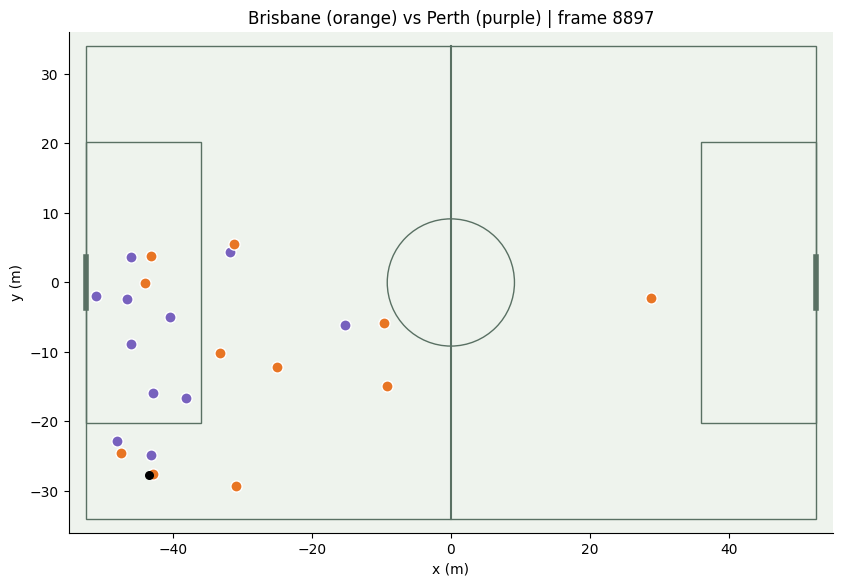

In [3]:
motion = movement(long)
frames = choose_sequence(motion, wide)
frame = int(frames[len(frames)//2])
print('Selected contiguous clip:', int(frames[0]), 'to', int(frames[-1]))
print('Tracking time:', wide.loc[wide.frame_id.eq(frame),'timestamp'].iloc[0])
frame_plot(motion, wide, frame)
plt.show()

### Animate the same sequence
The embedded HTML animation works without ffmpeg. Colors identify teams, not possession. Native coordinates retain stadium orientation; check attacking direction before any goal-value calculation.

In [4]:
from matplotlib.animation import FuncAnimation
fig, ax = plt.subplots(figsize=(9,6))
def draw(i):
    ax.clear()
    frame_plot(motion, wide, int(frames[i]), ax)
anim = FuncAnimation(fig, draw, frames=len(frames), interval=100)
html_animation = anim.to_jshtml()
plt.close(fig)
display(HTML(html_animation))

## B. Physical metrics: SkillCorner definitions, transparent estimates
In the documented men's context, HSR is 20–25 km/h and sprinting is above 25 km/h. Our code assigns [20,25) to HSR and [25,∞) to sprint to avoid double counting. This exact boundary convention is a teaching choice.

Distance ≈ Σ speed(m/s) × Δt. Missing data are excluded, never interpreted as zero exertion. Results describe the sample, not a match. Do not compare these estimates directly with official player-season aggregates.

**Effort rule here:** at least 1 s continuously above threshold; no gap merging. SkillCorner's exact production effort/filter rules are not reproduced. PSV-99 is defined over physical activities above 15 km/h; a 99th percentile over all tracking rows is not a faithful reproduction. Peak Velocity is a separate metric.

,player_id,name,valid_seconds,coverage,distance_m,hsr_m,sprint_m
15,795530,N. Pennington,600.4,0.98,1831.08,127.55,6.61
20,966112,A. Bugarija,601.4,0.98,1785.70,113.93,0.00
1,287934,Walid Shour,600.5,0.98,1738.02,133.44,68.56
12,560986,K. Jelacic,599.8,0.97,1676.35,195.59,59.75
7,51694,T. Gomulka,598.3,0.97,1667.31,89.38,8.54
13,560987,T. Ostler,601.6,0.98,1665.92,167.98,22.13
8,560882,F. Bérenguer,598.0,0.97,1593.42,97.81,19.35
9,560983,A. Burke-Gilroy,602.7,0.98,1592.59,148.69,97.18
17,797298,A. Zimarino,600.5,0.98,1582.17,149.36,31.78
4,51002,J. O'Shea,602.7,0.98,1570.66,163.37,0.69


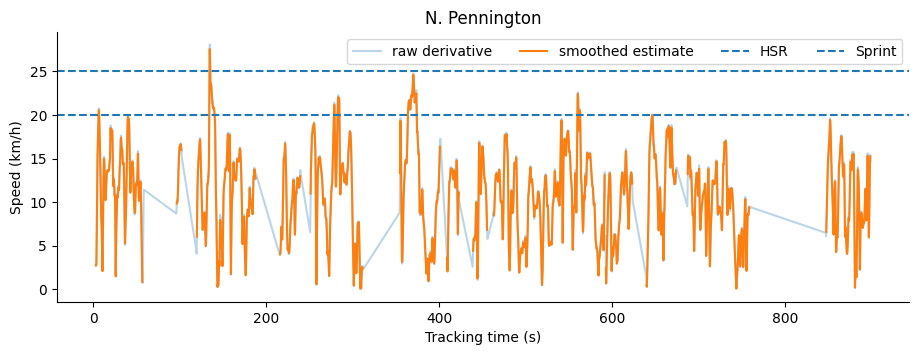

,start,end,duration_s,peak_kmh


In [5]:
summary = physical_summary(motion)
display(summary.head(10).round(2))
player_id = summary.iloc[0].player_id
g = motion[motion.player_id.eq(player_id)].sort_values('frame_id')
fig,ax=plt.subplots(figsize=(11,3.5))
ax.plot(g.seconds,g.raw_speed_kmh,alpha=.3,label='raw derivative')
ax.plot(g.seconds,g.speed_kmh,label='smoothed estimate')
for v,label in [(20,'HSR'),(25,'Sprint')]: ax.axhline(v,ls='--',label=label)
ax.set(xlabel='Tracking time (s)',ylabel='Speed (km/h)',title=g.name.iloc[0])
ax.legend(ncol=4); plt.show()
display(efforts(g))

### Interactive effort threshold
Change the duration or threshold to see why run counts depend on definitions. Time-to-HSR/sprint also needs a qualified starting state, start-time rule, and minimum data coverage; we explain those metrics in slides without claiming to reconstruct the official output.

In [6]:
@widgets.interact(threshold=(18.,30.,1.), min_duration=(.5,3.,.5))
def inspect_efforts(threshold=25.,min_duration=1.):
    display(efforts(g,threshold,min_duration))

interactive(children=(FloatSlider(value=25.0, description='threshold', max=30.0, min=18.0, step=1.0), FloatSli…

## Possession and event-detection cues
The nearest-player detector below leaves frames unassigned beyond a 2 m zone. Compare candidates with supplied player-possession labels. It does not implement a validated pass detector: ball motion, height, duels and timing require additional logic.

,frame_id,period_id,player_id,ball_distance,player_in_possession,candidate,change
0,40,1,51002,0.909340,51002,51002,False
1,41,1,51002,1.387083,51002,51002,False
2,42,1,51002,2.025562,51002,unassigned,True
3,43,1,51002,2.745269,None,unassigned,False
4,44,1,51002,3.503655,None,unassigned,False
5,45,1,51002,4.243018,None,unassigned,False
6,46,1,51002,4.922286,None,unassigned,False
7,47,1,51002,5.563596,None,unassigned,False
8,48,1,51002,6.237219,None,unassigned,False
9,49,1,287934,6.288283,None,unassigned,False


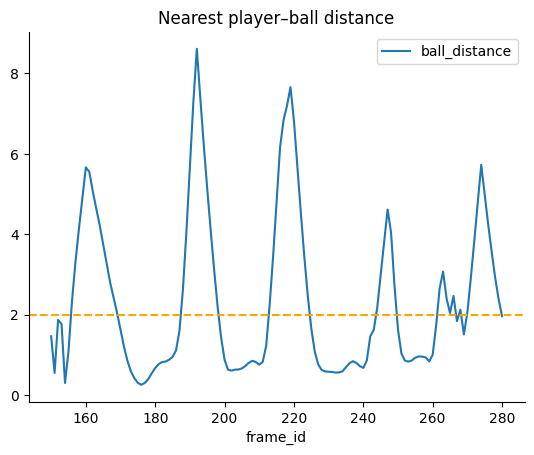

,player_id,x,y,n,line
0,287934,4.1380,3.4560,3426,3
1,51002,3.0540,-5.3550,3426,3
2,51043,7.0275,19.7800,3426,3
3,51050,16.3875,-10.0585,3426,2
4,560882,-10.5345,5.6390,3426,1
5,560983,2.4290,-21.6595,3426,3
6,560986,-10.3260,-11.2070,3426,1
7,795537,-15.6610,-2.2185,3426,1
8,797298,-12.0780,12.8830,3426,1
9,965697,17.3650,6.2000,3426,2


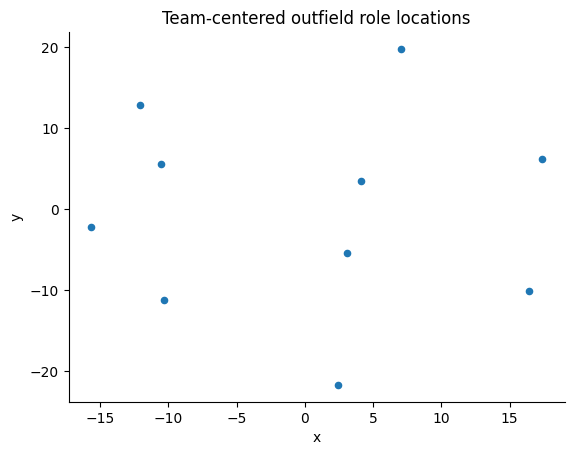

In [7]:
from analysis_tools import nearest_possession,centered_shape,line_clusters
candidates=nearest_possession(motion,wide)
display(candidates.head(12))
window=candidates[candidates.frame_id.between(150,280)]
window.plot(x='frame_id',y='ball_distance',title='Nearest player–ball distance')
plt.axhline(2,color='orange',ls='--');plt.show()
keepers={str(p['id']) for p in meta['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
shape=centered_shape(motion[~motion.player_id.isin(keepers)])
display(line_clusters(shape))
shape.plot.scatter(x='x',y='y',title='Team-centered outfield role locations');plt.show()

## C. Pitch-control notions: compare assumptions
**Voronoi:** nearest player owns each grid location. Fast, interpretable, but ignores velocity and ball travel.

**Gaussian influence:** aggregate smooth directional influence. Our covariance is illustrative, inspired by the family of methods, and does not reproduce Fernández/Bornn's exact parameterization. Team influence is converted to a bounded score; it is not a calibrated probability.

**Arrival-time baseline:** reaction delay + distance from a projected position / assumed speed. No ball-flight or interception integration; this is not a full Spearman pitch-control implementation.

Review the helper `surfaces` to inspect all assumptions.

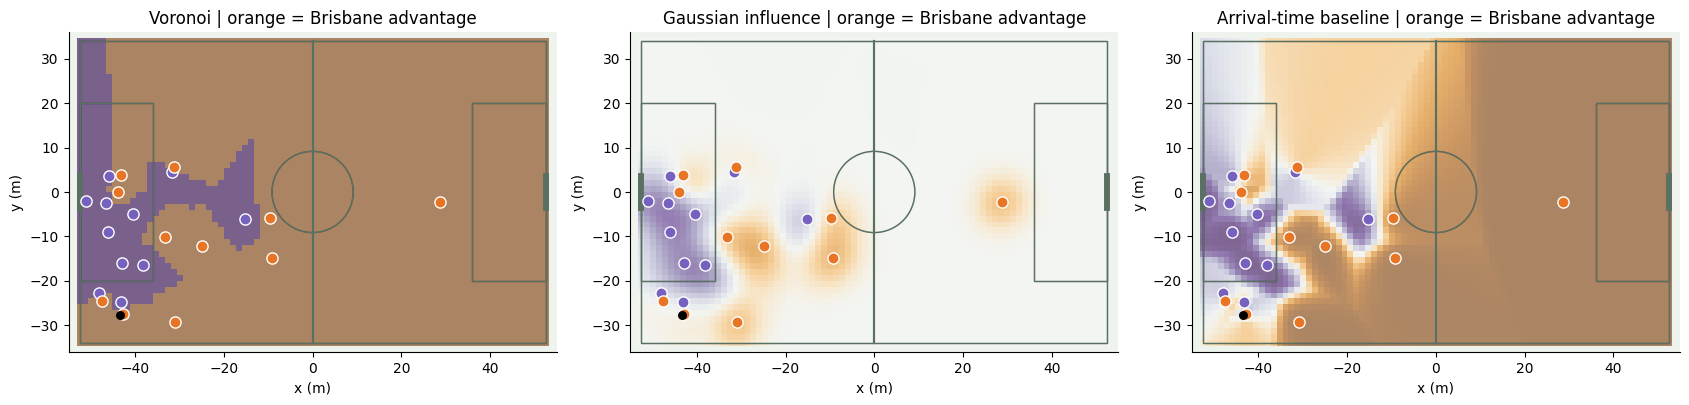

In [8]:
fig,axs=plt.subplots(1,3,figsize=(17,5))
for ax,model in zip(axs,['Voronoi','Gaussian influence','Arrival-time baseline']):
    control_plot(motion,wide,frame,model,ax)
plt.tight_layout();plt.show()

In [9]:
@widgets.interact(i=(0,len(frames)-1,1),model=['Voronoi','Gaussian influence','Arrival-time baseline'])
def inspect_control(i=len(frames)//2,model='Gaussian influence'):
    control_plot(motion,wide,int(frames[i]),model)
    plt.show()

interactive(children=(IntSlider(value=50, description='i', max=99), Dropdown(description='model', index=1, opt…

## Expected Threat before relational models
Use the fitted **DataBallPy open-play xT grid**, retained with attribution and its license. Location xT is based on event transitions, not trained from this tracking sample. Normalize attacking direction and map the 105 m pitch to the model's 106 m convention. An endpoint difference on an arbitrary tracked ball segment is not automatically a completed-pass value.

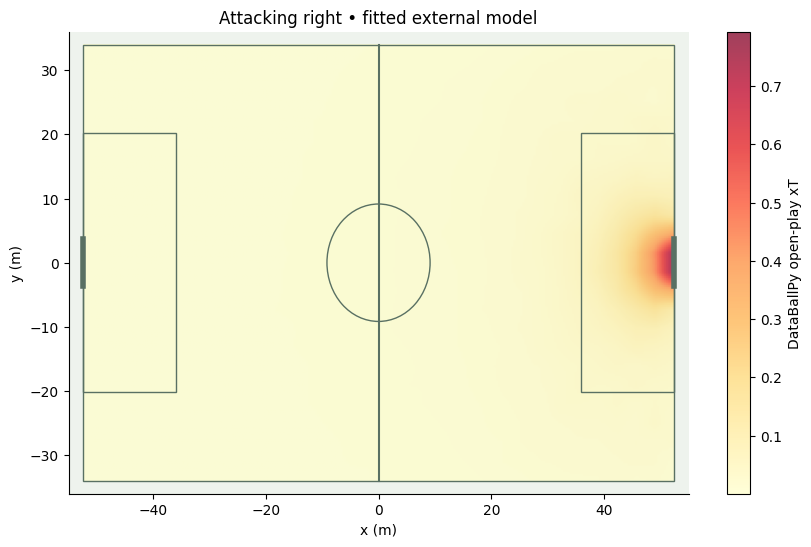

Observed ball endpoint difference: -0.026233188386783672


In [10]:
from analysis_tools import *
grid=xt_grid()
fig,ax=plt.subplots(figsize=(10,6));pitch(ax)
image=ax.imshow(grid.T,origin='lower',extent=(-52.5,52.5,-34,34),cmap='YlOrRd',alpha=.75,aspect='auto')
fig.colorbar(image,ax=ax,label='DataBallPy open-play xT');ax.set_title('Attacking right • fitted external model');plt.show()
start=wide[wide.frame_id.eq(int(frames[20]))].iloc[0]
end=wide[wide.frame_id.eq(int(frames[80]))].iloc[0]
# Brisbane attacks left in the first half: rotate both axes into attack-right coordinates.
v_start=xt_value(-start.ball_x*106/105,-start.ball_y)
v_end=xt_value(-end.ball_x*106/105,-end.ball_y)
print('Observed ball endpoint difference:',float(v_end-v_start))

## D. Accessible space, dangerous space and passing options
We now use the **actual public `accessible-space` implementation**, referenced by DataBallPy. It simulates passes across angles and speeds with potential receivers/interceptors. This differs from comparing Gaussian influence at the destination.

Explicitly inspect the first-half attacking direction, ball location, possession team, and velocity units. A goalkeeper-location heuristic supplies direction below; confirm it visually. The model's DAS is danger-weighted area, not EPV or calibrated goal probability. We use a modest grid for workshop speed.

The package respects offside by default. Its constraints, default parameters and treatment of simultaneous team access should be read alongside the [documentation](https://github.com/jonas-bischofberger/accessible-space).

In [11]:
import accessible_space
import inspect
print('Implementation:', inspect.signature(accessible_space.get_dangerous_accessible_space))
selected_frames = [int(frames[20]),int(frames[50]),int(frames[80])]
tracking_for_das = das_input(motion,wide,selected_frames)
display(tracking_for_das[['frame_id','player_id','team_id','team_in_possession','attacking_direction']].head())
print('Check goalkeeper positions against the plot:')
display(motion[motion.frame_id.eq(frame)].groupby('team_id').x.agg(['min','max','median']))
das_result = accessible_space.get_dangerous_accessible_space(
    tracking_for_das,period_col='period_id',attacking_direction_col='attacking_direction',
    infer_attacking_direction=False,player_in_possession_col='player_in_possession',n_angles=30,n_v0=8,radial_gridsize=3,
    use_progress_bar=False,additional_fields_to_return=['attack_poss_density'])
metrics=tracking_for_das[['frame_id']].copy()
metrics['AS_m2']=das_result.acc_space
metrics['DAS_weighted_m2']=das_result.das
display(metrics.drop_duplicates().round(2))

Implementation: (df_tracking, frame_col='frame_id', player_col='player_id', ball_player_id='ball', team_col='team_id', x_col='x', y_col='y', vx_col='vx', vy_col='vy', attacking_direction_col=None, period_col=<accessible_space.utility._Sentinel object at 0x0000024A21023770>, team_in_possession_col='team_in_possession', player_in_possession_col=None, x_pitch_min=-52.5, x_pitch_max=52.5, y_pitch_min=-34, y_pitch_max=34, infer_attacking_direction=True, exclude_passer=False, respect_offside=True, danger_weight=1, chunk_size=150, return_cropped_result=False, additional_fields_to_return=None, use_progress_bar=True, n_angles=30, phi_offset=0, n_v0=15, v0_min=3, v0_max=30, pass_start_location_offset=0, time_offset_ball=0, radial_gridsize=3, b0=-4.565680899844368, b1=-2000, player_velocity=9, keep_inertial_velocity=True, use_max=False, v_max=19.85563874348074, a_max=10.659091365334193, inertial_seconds=0.17, tol_distance=5, use_approx_two_point=True, v0_prob_aggregation_mode='mean', normalize=Tr

,frame_id,player_id,team_id,team_in_possession,attacking_direction
0,8867,11897,871,1802,-1
1,8867,287934,1802,1802,-1
2,8867,50982,871,1802,-1
3,8867,50999,1802,1802,-1
4,8867,51002,1802,1802,-1


Check goalkeeper positions against the plot:


,min,max,median
team_id,,,
871,-51.04,-15.21,-43.18
1802,-47.50,28.73,-31.21


,frame_id,AS_m2,DAS_weighted_m2
0,8867,1309.17,20.02
22,8897,2112.53,6.44
44,8927,3564.51,4.38


### Compare simulated passing surfaces
The surface shows modeled attacking accessibility. This surface is not an observed-pass outcome. Explain why risk, danger and actual decision selection are different targets.

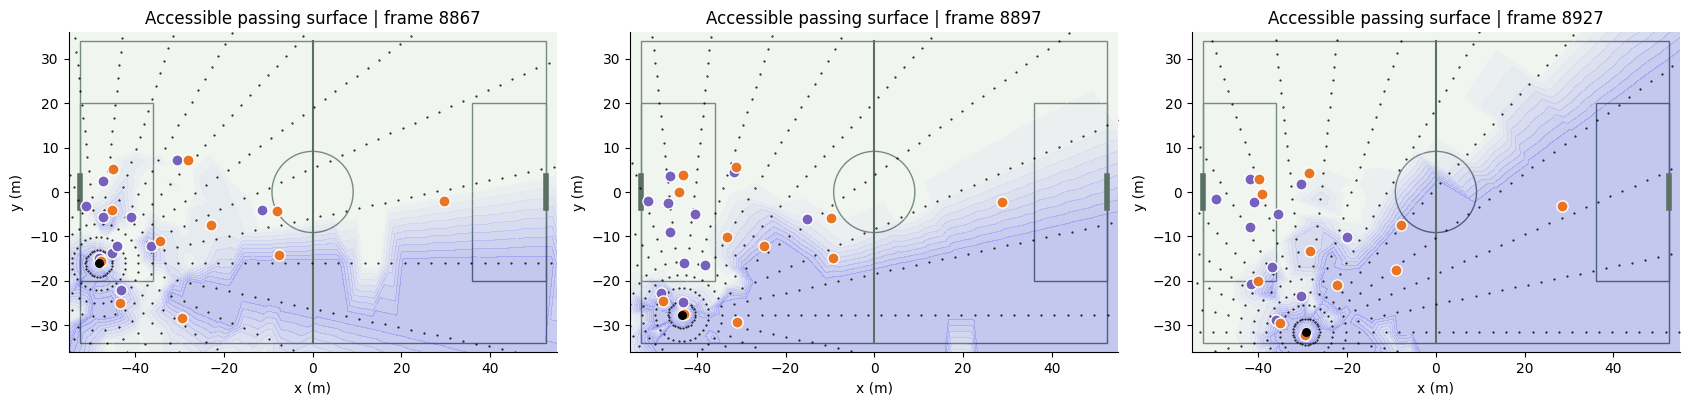

In [12]:
fig,axs=plt.subplots(1,3,figsize=(17,5))
for ax,k in zip(axs,range(3)):
    frame_plot(motion,wide,selected_frames[k],ax)
    plt.sca(ax)
    accessible_space.plot_expected_completion_surface(das_result.simulation_result,frame_index=k)
    ax.set_title(f'Accessible passing surface | frame {selected_frames[k]}')
plt.tight_layout();plt.show()

### Completion estimates for specified options
Take three teammate locations as hypothetical pass targets in one frame. These are **candidate options, not observed attempts or evidence of intent**. The model marginalizes over its ball-speed assumptions; calibration must be evaluated on labeled passes before interpreting values as reliable probabilities.

(df_passes, df_tracking, event_frame_col='frame_id', event_player_col='player_id', event_team_col='team_id', event_start_x_col='x', event_start_y_col='y', event_end_x_col='x_target', event_end_y_col='y_target', event_v0_col=None, tracking_frame_col='frame_id', tracking_player_col='player_id', tracking_team_col='team_id', tracking_x_col='x', tracking_y_col='y', tracking_vx_col='vx', tracking_vy_col='vy', tracking_v_col=None, tracking_team_in_possession_col=None, tracking_attacking_direction_col=None, tracking_period_col=<accessible_space.utility._Sentinel object at 0x0000024A21023770>, ball_tracking_player_id='ball', x_pitch_min=-52.5, x_pitch_max=52.5, y_pitch_min=-34, y_pitch_max=34, clip_to_pitch=True, use_event_coordinates_as_ball_position=True, use_event_team_as_team_in_possession=True, chunk_size=150, additional_fields_to_return=None, use_progress_bar=False, respect_offside=False, infer_attacking_direction=True, n_frames_after_pass_for_v0=5, fallback_v0=10, exclude_passer=True, us

,frame_id,player_id,team_id,x,y,x_target,y_target,xC_model
0,8897,560986,1802,-43.41,-27.65,-47.50,-24.51,0.548
1,8897,560986,1802,-43.41,-27.65,-33.15,-10.14,0.827
2,8897,560986,1802,-43.41,-27.65,-43.93,-0.06,0.255


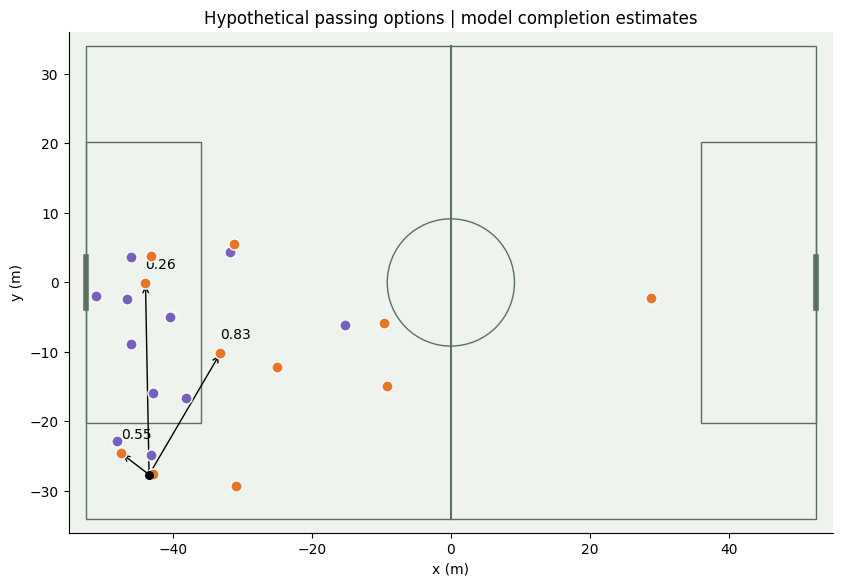

In [13]:
print(inspect.signature(accessible_space.get_expected_pass_completion))
poss_team = int(wide.loc[wide.frame_id.eq(selected_frames[1]),'ball_owning_team_id'].iloc[0])
ball_row = wide[wide.frame_id.eq(selected_frames[1])].iloc[0]
receivers = motion[motion.frame_id.eq(selected_frames[1]) & motion.team_id.eq(poss_team)].dropna(subset=['x','y','vx','vy']).copy()
receivers['distance_to_ball']=np.hypot(receivers.x-ball_row.ball_x,receivers.y-ball_row.ball_y)
passer=receivers.player_in_possession.iloc[0]
assert passer in set(receivers.player_id), 'Supplied ball carrier is not in the eligible player set.'
targets=receivers[receivers.player_id.ne(passer)].sort_values('distance_to_ball').iloc[[0,2,4]]
options=pd.DataFrame({'frame_id':selected_frames[1],'player_id':passer,'team_id':poss_team,
    'x':ball_row.ball_x,'y':ball_row.ball_y,'x_target':targets.x.to_numpy(),'y_target':targets.y.to_numpy()})
xc=accessible_space.get_expected_pass_completion(options,tracking_for_das,
    event_frame_col='frame_id',event_player_col='player_id',event_team_col='team_id',
    event_start_x_col='x',event_start_y_col='y',event_end_x_col='x_target',event_end_y_col='y_target',
    tracking_period_col='period_id',use_progress_bar=False)
options['xC_model']=xc.xc
display(options.round(3))
ax=frame_plot(motion,wide,selected_frames[1])
for r in options.itertuples():
    ax.annotate('',xy=(r.x_target,r.y_target),xytext=(r.x,r.y),arrowprops={'arrowstyle':'->','color':'black'})
    ax.text(r.x_target,r.y_target+2,f'{r.xC_model:.2f}',fontsize=10)
ax.set_title('Hypothetical passing options | model completion estimates');plt.show()

## Graphs: build the representation before discussing the network
Nodes are players; directed edges connect players within 15 m. Node features include position, velocity and team. Edge features include distance, relative position and team relationship. Changing the radius changes the graph; fully connected alternatives can model distant relationships.

A GNN learns shared message/update functions and task-specific readouts. This cell constructs inputs only: it does not train a GNN or claim EPV predictions. Reordering nodes should not change graph-level predictions when the architecture is designed appropriately.

,player_id,team_id,x,y,vx,vy
0,11897,871,-46.06,-8.91,0.497525,1.168859
1,287934,1802,-24.94,-12.11,-0.081260,-2.866007
2,50982,871,-45.97,3.67,1.000492,0.255035
3,50999,1802,28.73,-2.28,-0.153102,-0.323886
4,51002,1802,-33.15,-10.14,1.530708,-1.127981


,source,target,distance,dx,dy,same_team
0,11897,50982,12.580322,0.09,12.58,1
1,11897,51002,12.968462,12.91,-1.23,0
2,11897,51694,6.905317,5.65,3.97,1
3,11897,560882,9.102714,2.13,8.85,0
4,11897,560985,8.533774,-4.98,6.93,1


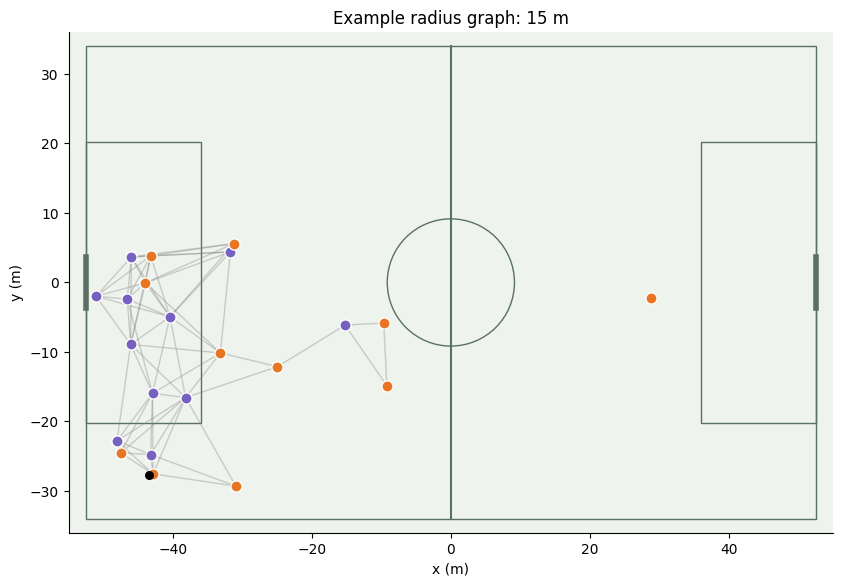

In [14]:
nodes=motion[motion.frame_id.eq(frame)].dropna(subset=['x','y','vx','vy']).reset_index(drop=True)
edges=graph_edges(nodes)
display(nodes[['player_id','team_id','x','y','vx','vy']].head())
display(edges.head())
ax=frame_plot(motion,wide,frame)
for e in edges.itertuples():
    if e.source > e.target: continue
    a=nodes[nodes.player_id.eq(e.source)].iloc[0]; b=nodes[nodes.player_id.eq(e.target)].iloc[0]
    ax.plot([a.x,b.x],[a.y,b.y],color='gray',alpha=.35,lw=1)
ax.set_title('Example radius graph: 15 m');plt.show()

## Temporal graph features and identity edges
Static graphs describe a moment. Add historical lagged features, changing spatial edges and identity links through time to represent change. Keep elapsed-time/gap masks. The code builds actual inputs; it does not train a temporal GNN. A frame GNN followed by a GRU, temporal convolution or causal attention are model choices with different assumptions.

These retrospective features use offline symmetric position smoothing; online prediction needs causal preprocessing or an explicit latency allowance.

In [15]:
from analysis_tools import temporal_features,temporal_edges
history=temporal_features(motion,frames)
display(history[['frame_id','player_id','speed_kmh','speed_kmh_lag10','speed_change_1s']].dropna().head())
edges_over_time=temporal_edges(motion,frames[:20])
display(edges_over_time.groupby('edge_type').size().to_frame('edge count'))
display(edges_over_time[edges_over_time.edge_type.eq('temporal')].head())
assert (edges_over_time.loc[edges_over_time.edge_type.eq('temporal'),'target_frame'] > edges_over_time.loc[edges_over_time.edge_type.eq('temporal'),'source_frame']).all()

,frame_id,player_id,speed_kmh,speed_kmh_lag10,speed_change_1s
132220,8857,11897,15.957346,13.765569,2.191777
132242,8858,11897,16.019786,13.987174,2.032612
132264,8859,11897,15.976556,14.175892,1.800664
132286,8860,11897,15.833642,14.366434,1.467208
132308,8861,11897,15.609182,14.580041,1.029142


,edge count
edge_type,
spatial,2814
temporal,418


,source,target,distance,dx,dy,same_team,source_frame,target_frame,edge_type,dt
2814,11897,11897,NaN,NaN,NaN,NaN,8847,8848,temporal,0.1
2815,11897,11897,NaN,NaN,NaN,NaN,8848,8849,temporal,0.1
2816,11897,11897,NaN,NaN,NaN,NaN,8849,8850,temporal,0.1
2817,11897,11897,NaN,NaN,NaN,NaN,8850,8851,temporal,0.1
2818,11897,11897,NaN,NaN,NaN,NaN,8851,8852,temporal,0.1


## Supplied SkillCorner run threat and pass EPV
These are supplied model fields, not predictions from our own EPV or GNN. Run xthreat is distinct from the event-location xT grid above. Interpret the provider's target and field definitions before combining values.

In [16]:
sample_events=events[events.frame_start.lt(9000)]
display(sample_events[sample_events.event_type.eq('off_ball_run')][['player_name','event_subtype','frame_start','xthreat']].dropna().head(10))
display(sample_events[sample_events.event_type.eq('player_possession')][['frame_start','end_type','pass_outcome','pass_epv_total','pass_epv_delta_for']].dropna(subset=['pass_epv_total']).head(10))

,player_name,event_subtype,frame_start,xthreat
1,T. Waddingham,run_ahead_of_the_ball,43,0.0047
10,B. Warland,dropping_off,162,0.0004
11,H. Van Der Saag,pulling_wide,164,0.0009
15,A. Burke-Gilroy,dropping_off,192,0.0006
19,J. O'Shea,coming_short,223,0.0020
25,A. Burke-Gilroy,support,244,0.0062
30,K. Jelacic,coming_short,260,0.0018
31,A. Burke-Gilroy,run_ahead_of_the_ball,260,0.0088
42,A. Bugarija,run_ahead_of_the_ball,315,0.0286
43,A. Faisal,support,320,0.0286


,frame_start,end_type,pass_outcome,pass_epv_total,pass_epv_delta_for
12,173,pass,successful,0.0002,-0.0003
16,202,pass,successful,0.0010,0.0006
20,226,pass,successful,0.0046,0.0039
26,251,pass,successful,0.0015,0.0010
33,265,pass,unsuccessful,-0.0117,-0.0068
36,281,pass,successful,0.0036,0.0019
38,299,pass,successful,0.0160,0.0160
52,358,pass,successful,-0.0158,-0.0156
58,378,pass,successful,0.0028,0.0028
64,402,pass,unsuccessful,-0.0204,-0.0202


## Supplied events and phase context
The following optional cells demonstrate supplied-label inspection, interval joins and shape summaries. They do not train an event detector, formation model, phase classifier, xG model or EPV model.

In [17]:
# Interval join within a period. Inspect phase taxonomy before interpreting summaries.
phase_rows=[]
for p in phases.itertuples():
    s=motion[(motion.period_id.eq(p.period)) & motion.frame_id.between(p.frame_start,p.frame_end)]
    if s.empty: continue
    shape=s.groupby(['frame_id','team_id']).agg(width=('y',lambda x:x.max()-x.min()),length=('x',lambda x:x.max()-x.min())).reset_index()
    shape['phase']=p.team_in_possession_phase_type
    shape['in_possession']=shape.team_id.eq(p.team_in_possession_id)
    phase_rows.append(shape)
phase_shapes=pd.concat(phase_rows,ignore_index=True)
display(phase_shapes.groupby(['phase','in_possession'])[['width','length']].median().round(1))
print('Shape includes goalkeepers; filter them before interpreting outfield compactness.')
display(events.loc[events.frame_start.between(wide.frame_id.min(),wide.frame_id.max()), ['event_type','event_subtype','player_name','frame_start']].head(15))

width  length
phase       in_possession               
build_up    False           35.5    60.5
            True            49.8    47.3
chaotic     False           30.5    64.5
            True            29.6    39.4
create      False           34.3    46.2
            True            50.4    54.4
direct      False           33.5    58.2
            True            45.9    55.6
finish      False           28.7    31.3
            True            37.9    64.5
quick_break False           36.9    41.9
            True            40.0    73.5
set_play    False           10.6    13.8
            True            31.1    63.2
transition  False           31.7    55.9
            True            32.2    63.9

Shape includes goalkeepers; filter them before interpreting outfield compactness.


,event_type,event_subtype,player_name,frame_start
1,off_ball_run,run_ahead_of_the_ball,T. Waddingham,43
2,player_possession,NaN,B. Warland,57
3,passing_option,NaN,T. Waddingham,57
4,player_possession,NaN,R. Warland,89
5,passing_option,NaN,A. Bugarija,89
6,passing_option,NaN,A. Faisal,91
7,on_ball_engagement,pressure,F. Bérenguer,134
8,on_ball_engagement,pressure,T. Waddingham,135
9,player_possession,NaN,A. Lebib,143
10,off_ball_run,dropping_off,B. Warland,162


## Discussion and extensions
- What changes if the same player is moving in the opposite direction?
- Does a larger area imply a more dangerous attack?
- How would you validate completion estimates, phase labels or event detection?
- What data would you need to distinguish run quality from teammate support?

**Further projects:** [DEFCON](https://github.com/hyunsungkim-ds/defcon), [U.S. Soccer counterattack GNN](https://github.com/USSoccerFederation/ussf_ssac_23_soccer_gnn), [TacticAI](https://www.nature.com/articles/s41467-024-45965-x), [SoccerMap](https://arxiv.org/abs/2010.10202).

Avoid random frame-level train/test splits: adjacent frames leak near-identical situations. Split by match/sequence, evaluate calibration and test coverage sensitivity. No trained EPV, xG or GNN artifact is included in this introductory workshop.